## Initialization

Import python libraries and variable definition

In [41]:
# Load libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import scale
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score
import os
import time
import warnings
warnings.filterwarnings("ignore")

# Parallel computing
import multiprocessing as mp
num_cores = mp.cpu_count()
print(f"Number of available cores: {num_cores}")

# Path
mypath = r"C:\Users\dmercier\OneDrive - ANSYS, Inc\pythonRepo\nanoMECommons\nanoindentation-and-EBSD-data-correlation-main_python"
os.chdir(mypath)

Number of available cores: 16


# Functions to be used

In [42]:
# fix plot theme for ggplot to ensure uniformity
def plot_theme():
    import matplotlib.pyplot as plt
    plt.rcParams['figure.figsize'] = (12, 8)
    plt.rcParams['font.size'] = 16
    plt.rcParams['axes.titlesize'] = 16
    plt.rcParams['axes.labelsize'] = 16
    plt.rcParams['xtick.labelsize'] = 16
    plt.rcParams['ytick.labelsize'] = 16
    plt.rcParams['legend.fontsize'] = 16
    plt.rcParams['lines.linewidth'] = 2
    plt.rcParams['lines.markersize'] = 10

    
# do distance based correlation for allocating colorshades to specific colors
# Function to compare RGB values with specific colors - more generic colors (maybe pale colors will be used)
# I play with it - choose colors for kColours as centers
def get_color_category(R, G, B):
    # Define standard RGB values for each color category
    colors_data = {
        'color': ['green', 'blue', 'red', 'yellow', 'pink', 'cyan', 'white', 'black'],
        'R': [0.4666667, 0.3529412, 0.6705882, 0.7921569, 0.8470588, 0.4901961, 1, 0],
        'G': [0.8313725, 0.3490196, 0.2784314, 0.8196078, 0.4313725, 0.8313725, 1, 0],
        'B': [0.4392157, 0.7843137, 0.2470588, 0.4000000, 0.6352941, 0.8156863, 1, 0]
    }

    # Function to find the closest color category for each row
    def find_closest_color(r, g, b):
        abs_diff = np.abs(np.array([colors_data['R'], colors_data['G'], colors_data['B']]) - np.array([r, g, b])).sum(axis=0)
        closest_color = colors_data['color'][np.argmin(abs_diff)]
        return closest_color

    # Apply the function to each row of R, G, and B
    color_categories = [find_closest_color(r, g, b) for r, g, b in zip(R, G, B)]
    return color_categories

# for data imputation with knn method
def impute_knn(train_data, test_data, k=8):
    # Separate predictors and response variables in the training set
    X_train = train_data[['x', 'y']]
    y_train = train_data[['R', 'G', 'B']]

    # Separate predictors in the test set
    X_test = test_data[['x', 'y']]

    # Use k-NN model to predict R, G, and B values for the test set
    imputed_data = test_data[['x', 'y']].copy()
    neigh = NearestNeighbors(n_neighbors=k)
    neigh.fit(X_train)
    _, indices = neigh.kneighbors(X_test)

    for col in ['R', 'G', 'B']:
        imputed_data[col] = y_train.iloc[indices].mean(axis=1)[col]

    return imputed_data

# Start: IPF map - read image to extract knowledge (anisotropy, grain locations, grains coordinates)
## Data Preparation - Phase #1

In [43]:
# Read IPF image
img = np.array(Image.open("IPF.jpg"))
img_dim = img.shape

# Assign RGB channels to data frame
img_wide = pd.DataFrame({
    'x': np.repeat(np.arange(img_dim[1]), img_dim[0]),
    'y': np.tile(np.arange(img_dim[0], 0, -1), img_dim[1]),
    'R': img[:, :, 0].flatten(),
    'G': img[:, :, 1].flatten(),
    'B': img[:, :, 2].flatten()
})

# Rescale coordinates
img_wide['x'] = (img_wide['x'] - 1) * 59.5 / img_wide['x'].max()
img_wide['y'] = (img_wide['y'] - 1) * 45.0 / img_wide['y'].max()

img_IPF = img_wide

# Round digits
img_wide['x'] = np.round(img_wide['x'], 1)
img_wide['y'] = np.round(img_wide['y'], 1)

img_wide['color'] = img_wide.apply(lambda row: f'rgb({row["R"]}, {row["G"]}, {row["B"]})', axis=1)

print(img_wide.head())

# Load the data
img_wide = pd.DataFrame({'R': img_wide['R'], 'G': img_wide['G'], 'B': img_wide['B'], 'x': img_wide['x'], 'y': img_wide['y']})

     x     y    R    G    B                     color
0 -0.1  44.9  222  126  164  rgb(222.0, 126.0, 164.0)
1 -0.1  44.9  222  126  164  rgb(222.0, 126.0, 164.0)
2 -0.1  44.8  219  124  164  rgb(219.0, 124.0, 164.0)
3 -0.1  44.8  215  120  160  rgb(215.0, 120.0, 160.0)
4 -0.1  44.7  214  119  161  rgb(214.0, 119.0, 161.0)


## IPF map clustering to obtain each grain's coordinates #

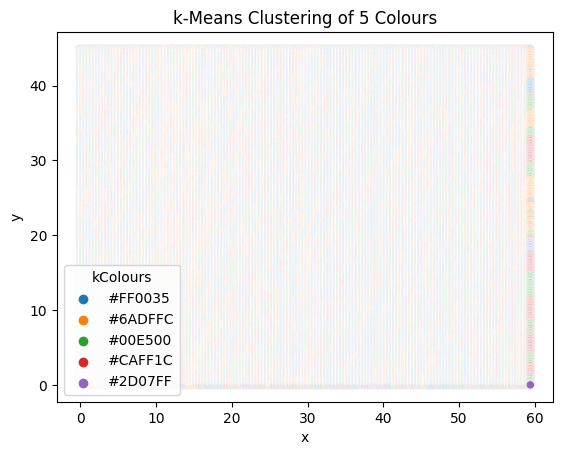

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

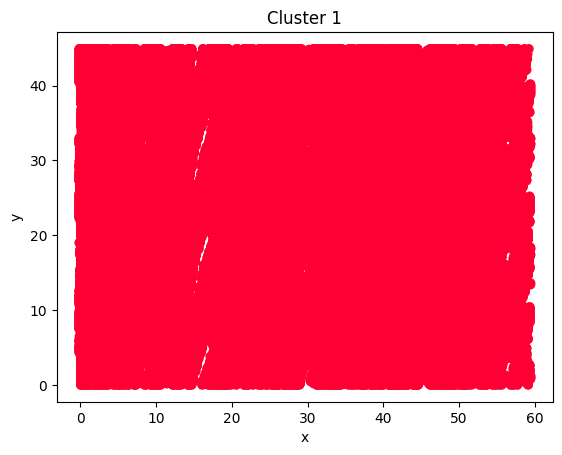

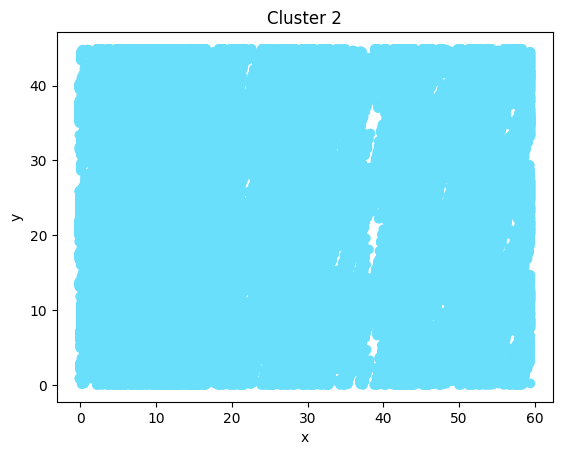

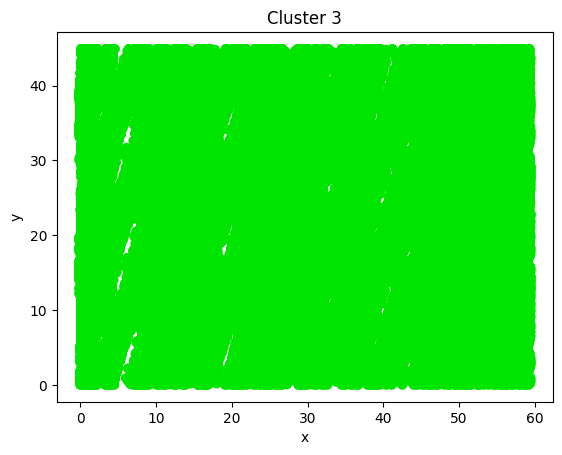

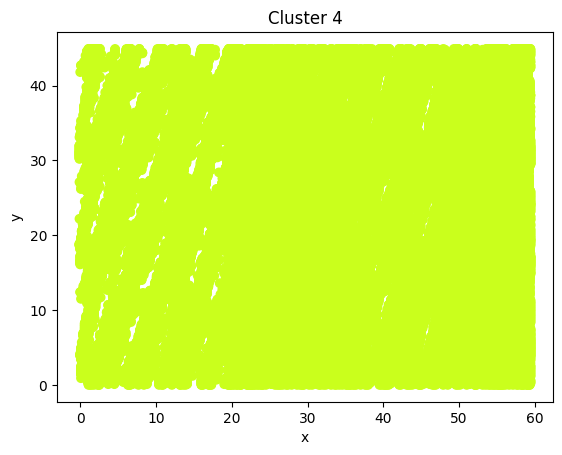

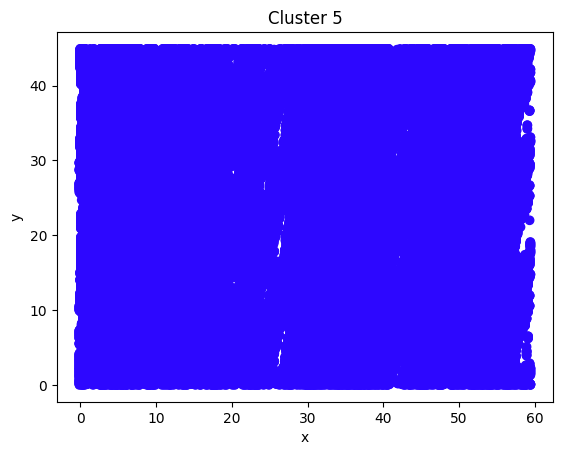

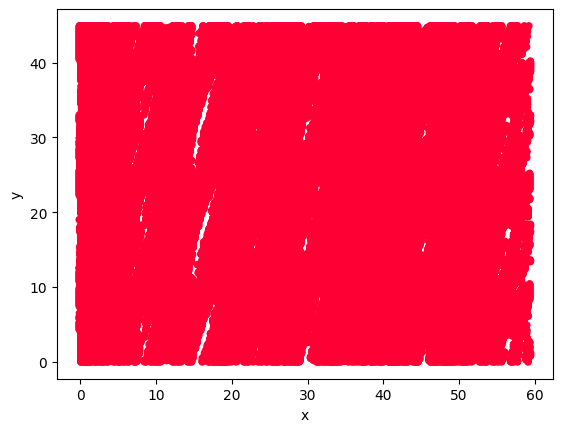

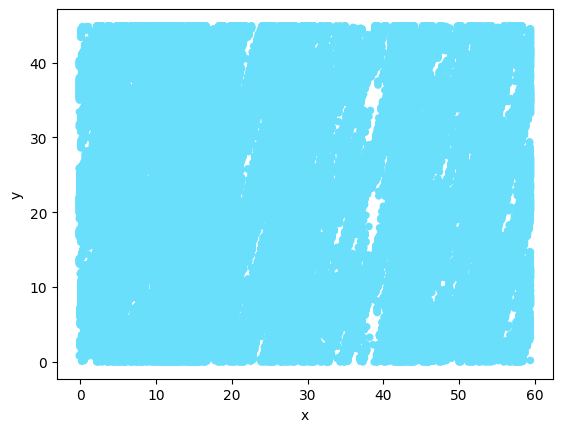

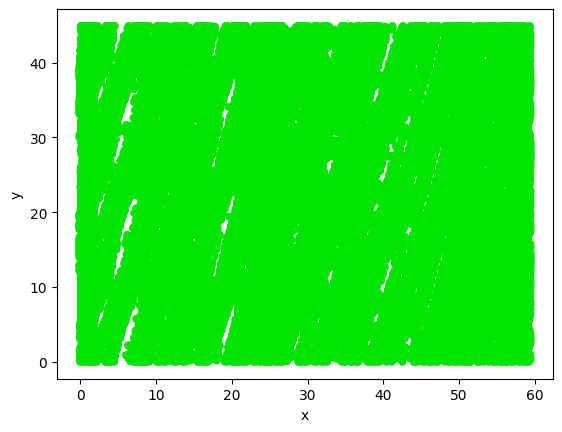

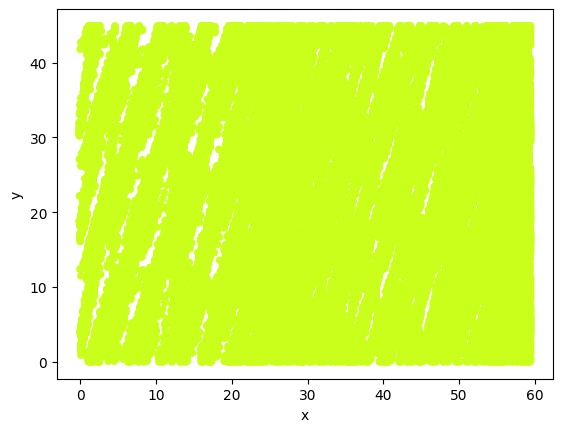

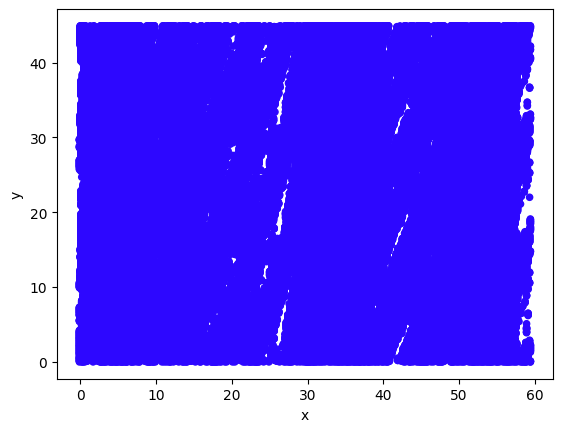

In [44]:
# Cluster the data
np.random.seed(1000)
kClusters = 5
kmeans = KMeans(n_clusters=kClusters, random_state=0).fit(img_wide[['R', 'G', 'B']])
img_wide['kColours'] = [f'#{int(r*255):02X}{int(g*255):02X}{int(b*255):02X}' for r, g, b in zip((kmeans.cluster_centers_[kmeans.labels_][:,0] - kmeans.cluster_centers_[kmeans.labels_][:,0].min()) / (kmeans.cluster_centers_[kmeans.labels_][:,0].max() - kmeans.cluster_centers_[kmeans.labels_][:,0].min()), (kmeans.cluster_centers_[kmeans.labels_][:,1] - kmeans.cluster_centers_[kmeans.labels_][:,1].min()) / (kmeans.cluster_centers_[kmeans.labels_][:,1].max() - kmeans.cluster_centers_[kmeans.labels_][:,1].min()), (kmeans.cluster_centers_[kmeans.labels_][:,2] - kmeans.cluster_centers_[kmeans.labels_][:,2].min()) / (kmeans.cluster_centers_[kmeans.labels_][:,2].max() - kmeans.cluster_centers_[kmeans.labels_][:,2].min()))]

# Plot the clustered data
sns.scatterplot(x='x', y='y', data=img_wide, hue='kColours')
plt.title(f'k-Means Clustering of {kClusters} Colours')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

# Convert kColours to RGB values
img_wide['red'] = img_wide['kColours'].str[1:3].apply(lambda x: int(x, 16)/255)
img_wide['green'] = img_wide['kColours'].str[3:5].apply(lambda x: int(x, 16)/255)
img_wide['blue'] = img_wide['kColours'].str[5:7].apply(lambda x: int(x, 16)/255)

# Check if colors are unique
col_df = img_wide['kColours'].unique()

# Create a plot for each data frame in the merged_list
plot_list = [plt.figure() for _ in range(len(col_df))]
for i, col_val in enumerate(col_df):
    df = img_wide[img_wide['kColours'] == col_val]
    plt.figure(plot_list[i].number)
    plt.scatter(df['x'], df['y'], c=df['kColours'])
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Cluster {i+1}')
    plt.show()

# Create a list of DataFrames for each unique color
merged_list = [img_wide[img_wide['kColours'] == col_val] for col_val in col_df]

# Use list comprehension to create a plot for each data frame in the merged_list
plot_list = [df.plot(kind='scatter', x='x', y='y', c=df['kColours'], colormap='viridis') for df in merged_list]



In [45]:
merged_list

[          R    G    B     x     y kColours  red  green      blue
 0       222  126  164  -0.1  44.9  #FF0035  1.0    0.0  0.207843
 1       222  126  164  -0.1  44.9  #FF0035  1.0    0.0  0.207843
 2       219  124  164  -0.1  44.8  #FF0035  1.0    0.0  0.207843
 3       215  120  160  -0.1  44.8  #FF0035  1.0    0.0  0.207843
 4       214  119  161  -0.1  44.7  #FF0035  1.0    0.0  0.207843
 ...     ...  ...  ...   ...   ...      ...  ...    ...       ...
 780496  185  108  152  59.4  18.1  #FF0035  1.0    0.0  0.207843
 780507  160  102  140  59.4  17.5  #FF0035  1.0    0.0  0.207843
 780508  139   60   55  59.4  17.4  #FF0035  1.0    0.0  0.207843
 780509  145   62   32  59.4  17.4  #FF0035  1.0    0.0  0.207843
 780510  146   76   42  59.4  17.3  #FF0035  1.0    0.0  0.207843
 
 [192847 rows x 9 columns],
           R    G    B     x     y kColours       red    green      blue
 79      152  172  161  -0.1  40.3  #6ADFFC  0.415686  0.87451  0.988235
 80      120  188  163  -0.1  40

## ISOLATE ALL GRAINS

In [57]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Create an empty list to store the processed dataframes
processed_dataframes = []

# Loop through each dataframe in the merged_list and perform the operations
for i, plot in enumerate(merged_list):
    # Get the current dataframe from the list
    data = pd.DataFrame(merged_list[i])

    # Get the cluster labels
    cluster_labels = kmeans_model.labels_

    data['PDA'] = cluster_labels
    data['PDA'] = data['PDA'] + 80*(i-1)+1

    # Perform the get_plane_annotation function and Apply the annotation and create a new column 'plane'
    data['plane'] = data.apply(lambda row: get_color_category(row['R'], row['G'], row['B']), axis=1)

    # Filter out rows where the value appears less than 25 times
    value_counts = data['PDA'].value_counts()
    threshold = 5
    data = data[data['PDA'].isin(value_counts[value_counts >= threshold].index)]

    # Save the processed dataframe in the list
    processed_dataframes.append(data)

# Combine the processed dataframes into a single dataframe
final_dataframe = pd.concat(processed_dataframes)

# Replace plane values based on color
color_to_plane = {
    'red': '(001)',
    'blue': '(111)',
    'green': '(101)',
    'cyan': '(101)U(111)',
    'yellow': '(001)U(101)',
    'pink': '(001)U(111)',
    'white': 'White',
    'black': 'Black'
}
final_dataframe['plane'] = final_dataframe['plane'].map(color_to_plane).fillna('NA')

# Display the first few rows of the dataframe
print(final_dataframe.head())

# Count the number of rows where plane is "", "NA", "White", and "Black"
print((final_dataframe['plane'] == "").sum())
print((final_dataframe['plane'] == "NA").sum())
print((final_dataframe['plane'] == "White").sum())
print((final_dataframe['plane'] == "Black").sum())

# Display the structure of the dataframe
print(final_dataframe.info())

# Check statistics
print((final_dataframe['plane'] == "(001)U(111)").sum())
print((final_dataframe['plane'] == "(001)").sum())
print((final_dataframe['plane'] == "(111)").sum())
print((final_dataframe['plane'] == "(001)U(101)").sum())
print((final_dataframe['plane'] == "(101)").sum())
print((final_dataframe['plane'] == "(101)U(111)").sum())

# Save the dataframe to a CSV file
final_dataframe.to_csv('IPF_grains_n_planes_repeat.csv', index=False)

     R    G    B    x     y kColours  red  green      blue
0  222  126  164 -0.1  44.9  #FF0035  1.0    0.0  0.207843
1  222  126  164 -0.1  44.9  #FF0035  1.0    0.0  0.207843
2  219  124  164 -0.1  44.8  #FF0035  1.0    0.0  0.207843
3  215  120  160 -0.1  44.8  #FF0035  1.0    0.0  0.207843
4  214  119  161 -0.1  44.7  #FF0035  1.0    0.0  0.207843


TypeError: 'float' object is not iterable

## Test how it looks like a grain

In [ ]:
# Filter the dataframe
test = final_dataframe[final_dataframe['PDA'] == 755]

# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=test, x='x', y='y', hue='kColours')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

# To count the number of unique grains, you can use the nunique function
# Assuming 'grain' is the column that identifies each grain
num_grains = test['grain'].nunique()
print(f'Number of unique grains: {num_grains}')

# To get the dimensions of each grain, you can group by the grain column and calculate the max and min of x and y
grain_dimensions = test.groupby('grain').agg({'x': ['min', 'max'], 'y': ['min', 'max']})
grain_dimensions['length'] = grain_dimensions[('x', 'max')] - grain_dimensions[('x', 'min')]
grain_dimensions['width'] = grain_dimensions[('y', 'max')] - grain_dimensions[('y', 'min')]
print(grain_dimensions)

## Test how it looks like a unique anisotropic plane

In [ ]:
# Filter the dataframe
planes = ["(001)", "(101)", "(111)", "(101)U(111)", "(001)U(101)", "(001)U(111)"]
test2 = final_dataframe[final_dataframe['plane'].isin(planes)]

# Display the first few rows of the dataframe
print(test2.head())

# Create a scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=test2, x='x', y='y', hue='kColours', s=15)
plt.title('EBSD pattern')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

# Display the unique colors
print(test2['kColours'].unique())

## Apply necessary corrections to IPF classification

In [ ]:
# Create a dictionary mapping colors to planes
color_to_plane = {
    "#C48B54": "(001)",
    "#D6A670": "(001)",
    "#808DD8": "(111)",
    "#74A9DA": "(111)",
    "#6CCEA8": "(101)",
    "#A4CFB1": "(101)",
    "#D56F68": "(001)",
    "#D08480": "(001)"
}

# Replace the 'plane' values based on their color
final_dataframe['plane'] = final_dataframe['kColours'].map(color_to_plane).fillna(final_dataframe['plane'])